In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os


In [1]:
df = pd.read_excel("data/Prestamos_Data_Alumnos_v5.xlsx",engine="openpyxl")
df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estudios,Tipo_Jornada_Laboral,Estado_Civil,Posesion_Hipoteca,Personas_Cargo,Proposito,Fiador,Impago,Prima
0,O77MPJ,26,19153.0,6973,706,9.0,1,19.05,36.0,0.10,Grado Universitario,Jornada completa,Soltero,0.0,1.0,Automóvil,1.0,1,130.83
1,6B4H6E,22,16000.0,10000,769,22.0,1,8.96,48.0,0.32,Escolar,Desempleado,Soltero,1.0,1.0,Vivienda,0.0,0,65.85
2,VKTUXP,33,38308.0,16474,699,70.0,3,14.07,36.0,0.20,Máster,Jornada completa,Casado,1.0,1.0,Vivienda,0.0,0,260.60
3,5P9OVL,51,51271.0,40770,812,309.0,1,12.66,12.0,0.36,Grado Universitario,Jornada completa,Casado,0.0,1.0,Vivienda,1.0,0,221.02
4,KG9CT9,34,56572.0,73978,763,86.0,1,13.91,60.0,0.55,Máster,Tiempo parcial,Soltero,0.0,0.0,Educación,0.0,0,800.00


In [2]:
df.info

<bound method DataFrame.info of             ID  Edad  Ingresos  Monto_Inicial  Scoring_Crediticio  \
0       O77MPJ    26   19153.0           6973                 706   
1       6B4H6E    22   16000.0          10000                 769   
2       VKTUXP    33   38308.0          16474                 699   
3       5P9OVL    51   51271.0          40770                 812   
4       KG9CT9    34   56572.0          73978                 763   
...        ...   ...       ...            ...                 ...   
510699  MY63P5    28   17390.0           5000                 744   
510700  6903JQ    42   33486.0          33048                 760   
510701  EPB8QX    64   40369.0          40000                 680   
510702  R1QRKW    35   30915.0         130966                 739   
510703  Q90VE4    28   25765.0           6515                 788   

        Meses_Empleo  Num_Creditos  Ratio_Interes  Duracion  \
0                9.0             1          19.05      36.0   
1            

In [3]:
df.dtypes

ID                       object
Edad                      int64
Ingresos                float64
Monto_Inicial             int64
Scoring_Crediticio        int64
Meses_Empleo            float64
Num_Creditos              int64
Ratio_Interes           float64
Duracion                float64
Ratio_Deuda_Ingresos    float64
Estudios                 object
Tipo_Jornada_Laboral     object
Estado_Civil             object
Posesion_Hipoteca       float64
Personas_Cargo          float64
Proposito                object
Fiador                  float64
Impago                    int64
Prima                   float64
dtype: object

In [4]:
# mirar cuantos duplicados hay
df['Proposito'].duplicated().value_counts()

Proposito
True     510698
False         6
Name: count, dtype: int64

In [5]:
# hacemos copia por si acaso
copia = df.copy()

In [6]:
copia.shape


(510704, 19)

In [7]:

#filtrar por vivienda => lo que nos toca
copia = copia[copia["Proposito"] == "Vivienda"]
copia.head()


,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estudios,Tipo_Jornada_Laboral,Estado_Civil,Posesion_Hipoteca,Personas_Cargo,Proposito,Fiador,Impago,Prima
1,6B4H6E,22,16000.0,10000,769,22.0,1,8.96,48.0,0.32,Escolar,Desempleado,Soltero,1.0,1.0,Vivienda,0.0,0,65.85
2,VKTUXP,33,38308.0,16474,699,70.0,3,14.07,36.0,0.20,Máster,Jornada completa,Casado,1.0,1.0,Vivienda,0.0,0,260.60
3,5P9OVL,51,51271.0,40770,812,309.0,1,12.66,12.0,0.36,Grado Universitario,Jornada completa,Casado,0.0,1.0,Vivienda,1.0,0,221.02
10,YL0W8G,30,31923.0,36707,813,43.0,1,8.96,24.0,0.32,Grado Universitario,Jornada completa,Casado,0.0,1.0,Vivienda,0.0,0,125.00
13,YP8WTV,28,27373.0,86981,765,60.0,2,10.07,48.0,0.55,Escolar,Jornada completa,Soltero,0.0,1.0,Vivienda,0.0,0,800.00


In [8]:

copia['Proposito'].value_counts()


Proposito
Vivienda    101899
Name: count, dtype: int64

In [9]:
copia.duplicated().sum()

np.int64(4)

In [10]:
# ver las filas de duplicados
duplicados=copia[copia.duplicated()]
duplicados


,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estudios,Tipo_Jornada_Laboral,Estado_Civil,Posesion_Hipoteca,Personas_Cargo,Proposito,Fiador,Impago,Prima
328169,AIJ783,52,46929.0,59359,683,427.0,2,14.76,36.0,0.36,Escolar,Jornada completa,Casado,1.0,1.0,Vivienda,0.0,0,760.00
425985,N3L8A6,22,18553.0,40000,805,20.0,3,13.04,60.0,0.55,Escolar,Jornada completa,Soltero,0.0,0.0,Vivienda,1.0,0,468.83
480472,TTGYVO,36,35293.0,40000,785,136.0,1,6.85,36.0,0.24,Grado Universitario,Jornada completa,Casado,0.0,1.0,Vivienda,0.0,0,292.69
501642,M60ASI,55,41241.0,49993,575,525.0,1,12.61,24.0,0.46,Escolar,Jornada completa,Soltero,0.0,0.0,Vivienda,0.0,0,580.00


In [11]:

id_dup=copia[copia['ID']=='AIJ783']
id_dup


,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estudios,Tipo_Jornada_Laboral,Estado_Civil,Posesion_Hipoteca,Personas_Cargo,Proposito,Fiador,Impago,Prima
225638,AIJ783,52,46929.0,59359,683,427.0,2,14.76,36.0,0.36,Escolar,Jornada completa,Casado,1.0,1.0,Vivienda,0.0,0,760.0
328169,AIJ783,52,46929.0,59359,683,427.0,2,14.76,36.0,0.36,Escolar,Jornada completa,Casado,1.0,1.0,Vivienda,0.0,0,760.0


In [12]:
copia=copia.drop_duplicates()

In [13]:
copia.duplicated().sum()

np.int64(0)

In [14]:
#mirar valores nulos
copia.isna().sum()

ID                      0
Edad                    0
Ingresos                0
Monto_Inicial           0
Scoring_Crediticio      0
Meses_Empleo            0
Num_Creditos            0
Ratio_Interes           0
Duracion                1
Ratio_Deuda_Ingresos    1
Estudios                2
Tipo_Jornada_Laboral    1
Estado_Civil            0
Posesion_Hipoteca       2
Personas_Cargo          1
Proposito               0
Fiador                  1
Impago                  0
Prima                   1
dtype: int64

### Sustituir los nulos por la media-> solo las variables numéricas

In [15]:
#sustituir nulos por las medias
media_duracion = copia['Duracion'].mean()

copia['Duracion']=copia['Duracion'].fillna(media_duracion)

In [16]:
# Columna 'Duracion'
media_duracion = copia['Duracion'].mean()

copia['Duracion']=copia['Duracion'].fillna(media_duracion)

# Columna 'Ratio_Deuda_Ingresos'
media_ratio_deuda_ingreso = copia['Ratio_Deuda_Ingresos'].mean()

copia['Ratio_Deuda_Ingresos']=copia['Ratio_Deuda_Ingresos'].fillna(media_ratio_deuda_ingreso)

# Columna 'Posesion_Hipoteca'
media_posesion_hipoteca = copia['Posesion_Hipoteca'].mean()

copia['Posesion_Hipoteca']=copia['Posesion_Hipoteca'].fillna(media_ratio_deuda_ingreso)

# Columna 'Personas_cargo'
media_personas_cargo = copia['Personas_Cargo'].mean()

copia['Personas_Cargo']=copia['Personas_Cargo'].fillna(media_personas_cargo)

# Columna 'Fiador'
media_fiador = copia['Fiador'].mean()

copia['Fiador']=copia['Fiador'].fillna(media_fiador)

# Columna 'Prima'
media_prima = copia['Prima'].mean()

copia['Prima']=copia['Prima'].fillna(media_prima)


In [17]:
# Mirar si hay alguna columna numérica con algun nulo pendiente
copia.isna().sum()

ID                      0
Edad                    0
Ingresos                0
Monto_Inicial           0
Scoring_Crediticio      0
Meses_Empleo            0
Num_Creditos            0
Ratio_Interes           0
Duracion                0
Ratio_Deuda_Ingresos    0
Estudios                2
Tipo_Jornada_Laboral    1
Estado_Civil            0
Posesion_Hipoteca       0
Personas_Cargo          0
Proposito               0
Fiador                  0
Impago                  0
Prima                   0
dtype: int64

In [18]:
# Vemos que las dos columnas con nulos son columnas categóricas por lo que el siguiente paso es imputar esos nulos

In [19]:
copia.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estudios,Tipo_Jornada_Laboral,Estado_Civil,Posesion_Hipoteca,Personas_Cargo,Proposito,Fiador,Impago,Prima
1,6B4H6E,22,16000.0,10000,769,22.0,1,8.96,48.0,0.32,Escolar,Desempleado,Soltero,1.0,1.0,Vivienda,0.0,0,65.85
2,VKTUXP,33,38308.0,16474,699,70.0,3,14.07,36.0,0.20,Máster,Jornada completa,Casado,1.0,1.0,Vivienda,0.0,0,260.60
3,5P9OVL,51,51271.0,40770,812,309.0,1,12.66,12.0,0.36,Grado Universitario,Jornada completa,Casado,0.0,1.0,Vivienda,1.0,0,221.02
10,YL0W8G,30,31923.0,36707,813,43.0,1,8.96,24.0,0.32,Grado Universitario,Jornada completa,Casado,0.0,1.0,Vivienda,0.0,0,125.00
13,YP8WTV,28,27373.0,86981,765,60.0,2,10.07,48.0,0.55,Escolar,Jornada completa,Soltero,0.0,1.0,Vivienda,0.0,0,800.00


In [20]:
copia['Estudios'].value_counts()

Estudios
Escolar                39637
Grado Universitario    37919
Máster                 16241
Doctorado               8096
Name: count, dtype: int64

In [21]:
copia['Estudios'] = copia['Estudios'].fillna('Escolar')

In [22]:
# Hacemos lo mismo con la columna 'Tipo_Jornada_Laboral'
copia['Tipo_Jornada_Laboral'].value_counts()

Tipo_Jornada_Laboral
Jornada completa    56048
Tiempo parcial      20575
Autónomo            15132
Desempleado         10139
Name: count, dtype: int64

In [23]:
copia['Tipo_Jornada_Laboral'] = copia['Tipo_Jornada_Laboral'].fillna('Jornada completa')

In [24]:
copia.isna().sum()

ID                      0
Edad                    0
Ingresos                0
Monto_Inicial           0
Scoring_Crediticio      0
Meses_Empleo            0
Num_Creditos            0
Ratio_Interes           0
Duracion                0
Ratio_Deuda_Ingresos    0
Estudios                0
Tipo_Jornada_Laboral    0
Estado_Civil            0
Posesion_Hipoteca       0
Personas_Cargo          0
Proposito               0
Fiador                  0
Impago                  0
Prima                   0
dtype: int64

### CORRELACIÓN DE VARIABLES

In [25]:
# Calculamos la correlación entre todas las variables, sin tener en cuenta las variables categóricas

In [26]:
copia.columns

Index(['ID', 'Edad', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio',
       'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes', 'Duracion',
       'Ratio_Deuda_Ingresos', 'Estudios', 'Tipo_Jornada_Laboral',
       'Estado_Civil', 'Posesion_Hipoteca', 'Personas_Cargo', 'Proposito',
       'Fiador', 'Impago', 'Prima'],
      dtype='object')

In [27]:
copia.dtypes

ID                       object
Edad                      int64
Ingresos                float64
Monto_Inicial             int64
Scoring_Crediticio        int64
Meses_Empleo            float64
Num_Creditos              int64
Ratio_Interes           float64
Duracion                float64
Ratio_Deuda_Ingresos    float64
Estudios                 object
Tipo_Jornada_Laboral     object
Estado_Civil             object
Posesion_Hipoteca       float64
Personas_Cargo          float64
Proposito                object
Fiador                  float64
Impago                    int64
Prima                   float64
dtype: object

In [28]:
copia.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estudios,Tipo_Jornada_Laboral,Estado_Civil,Posesion_Hipoteca,Personas_Cargo,Proposito,Fiador,Impago,Prima
1,6B4H6E,22,16000.0,10000,769,22.0,1,8.96,48.0,0.32,Escolar,Desempleado,Soltero,1.0,1.0,Vivienda,0.0,0,65.85
2,VKTUXP,33,38308.0,16474,699,70.0,3,14.07,36.0,0.20,Máster,Jornada completa,Casado,1.0,1.0,Vivienda,0.0,0,260.60
3,5P9OVL,51,51271.0,40770,812,309.0,1,12.66,12.0,0.36,Grado Universitario,Jornada completa,Casado,0.0,1.0,Vivienda,1.0,0,221.02
10,YL0W8G,30,31923.0,36707,813,43.0,1,8.96,24.0,0.32,Grado Universitario,Jornada completa,Casado,0.0,1.0,Vivienda,0.0,0,125.00
13,YP8WTV,28,27373.0,86981,765,60.0,2,10.07,48.0,0.55,Escolar,Jornada completa,Soltero,0.0,1.0,Vivienda,0.0,0,800.00


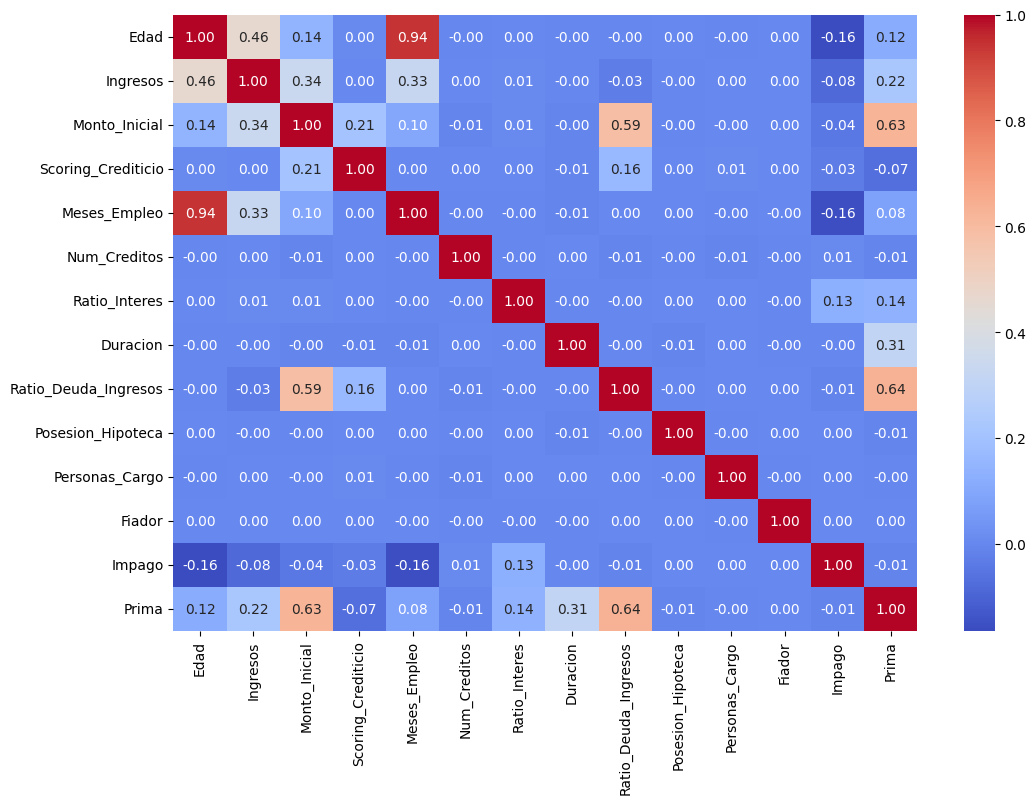

In [ ]:
variables = ['Edad', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio',
       'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes', 'Duracion',
       'Ratio_Deuda_Ingresos', 'Posesion_Hipoteca', 'Personas_Cargo', 'Fiador', 'Impago', 'Prima']
correlacion = copia[variables].corr()
plt.figure(figsize = (12,8))
sns.heatmap(correlacion, annot=True, cmap='coolwarm', fmt='.2f')

plt.show()

### Guardamos copia como csv

In [30]:
copia.shape

(101895, 19)

In [33]:
copia.to_csv("df_limpio.csv", index=False)

In [34]:

print(os.path.exists("df_limpio.csv"))

True
